### Background
- We want to learn about Logistic Regression as a method for **Classification**
- Some examples of classification problems:
  + Spam vs "Ham" emails
  + Loan Default (Y/N)
  + Disease Diagnosis
- Above were all examples of Binary Classification

- So far we've seen regression problems where we try to predict a continous value.
- Although the name maybe confusing at first, logistic regression allows us to solve classification problems, where we are trying to predict discrete categories
- The convension for binary classification is to have two classes 0 and 1
- We **can't** use a linear regression model on a binary groups. It won't lead to a good fit
- Instead we can transform our linear regression to a logistic regression curve
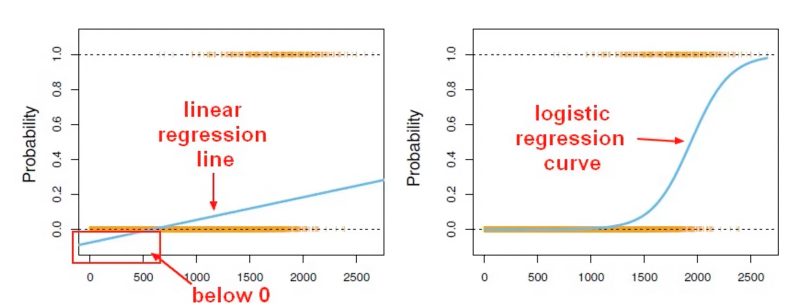

- The logistic function (Sigmoid) takes in any value and outputs it to be between 0 and 1
  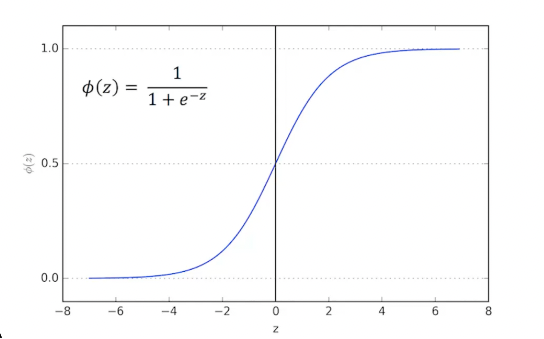

- 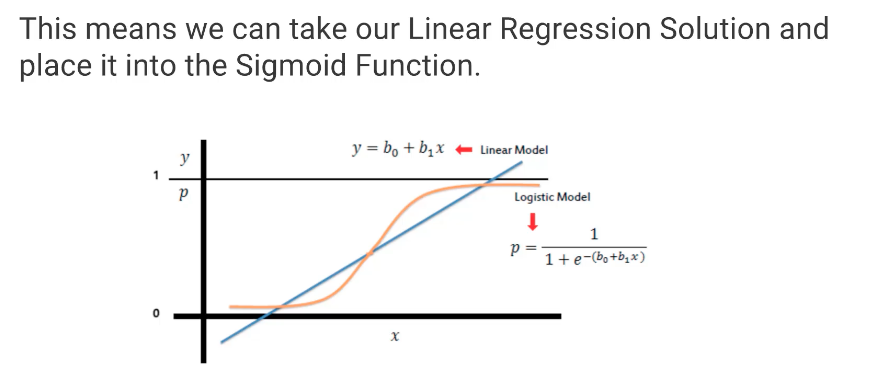

- We can set a cutoff point at 0.5, anything below it results in class 0, anything above is class 1.
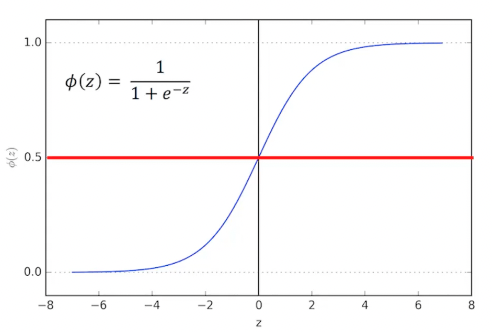

### Model Evaluation
- You can use a confusion matrix to evaluate our model
- Eg, image testing for disease
  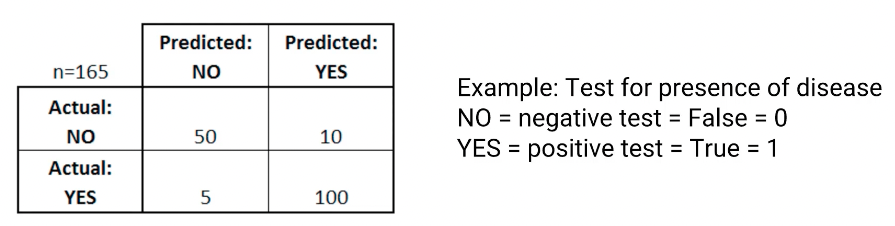

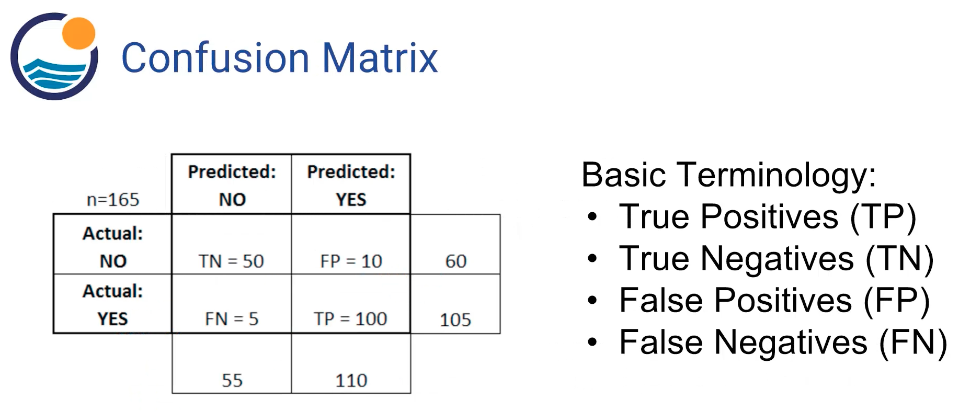
- In this case, the model is 150/165 = 91% correct
- How often the model is wrong: (FP + FN)/total = 15/165 = 0.09
- 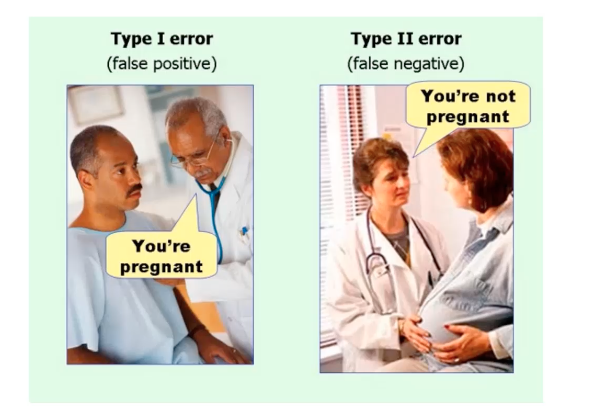

# Logistic Regression with Python

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [8]:
train = pd.read_csv('Refactored_Py_DS_ML_Bootcamp-master 2/13-Logistic-Regression/titanic_train.csv')

In [9]:
train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


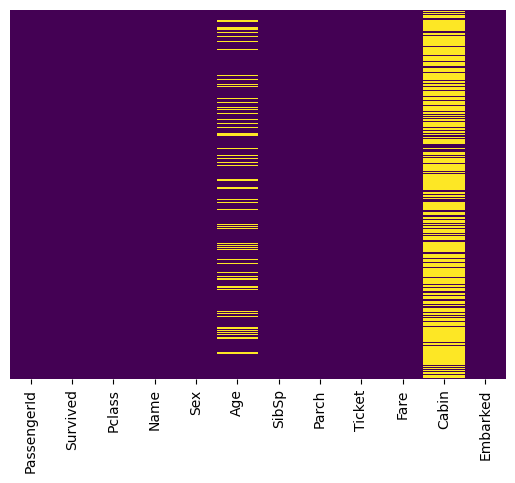

In [10]:
# just do a heatmap to see the heatmap of missing information in the dataset
sns.heatmap(train.isnull(), yticklabels=False, cbar=False, cmap='viridis')
plt.show()

In [11]:
sns.set_style('whitegrid')

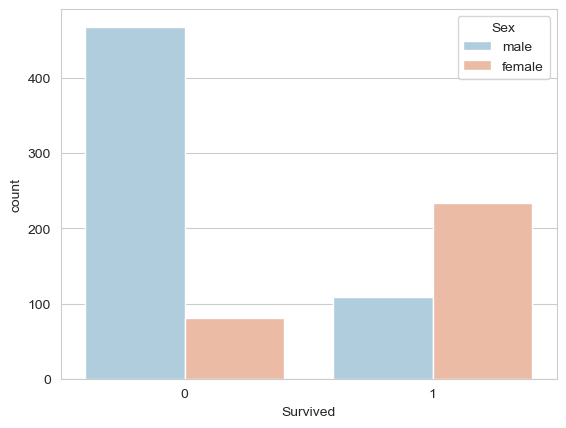

In [12]:
sns.countplot(x='Survived', hue = 'Sex', data = train, palette = 'RdBu_r')
plt.show()

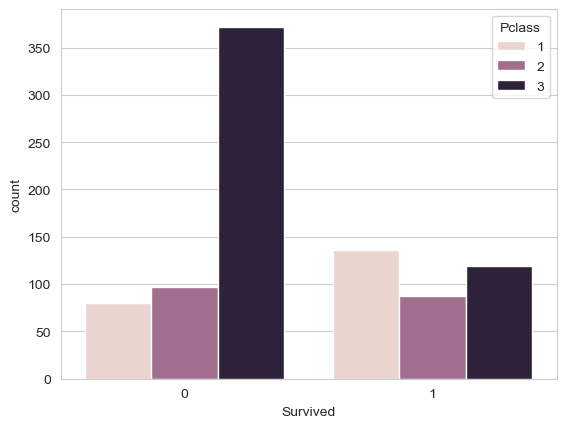

In [13]:
sns.countplot(x='Survived', hue = 'Pclass', data = train)
plt.show()

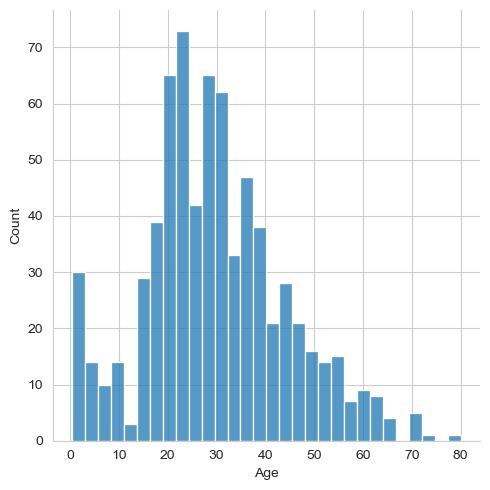

In [14]:
# see the distribution of age
sns.displot(train['Age'].dropna(), kde = False, bins=30)
plt.show()

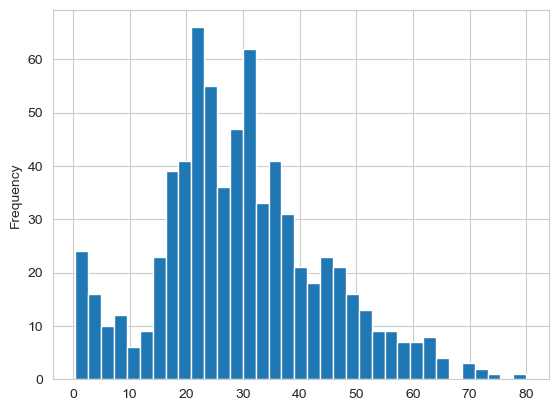

In [15]:
train['Age'].plot.hist(bins=35)
plt.show()

In [16]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


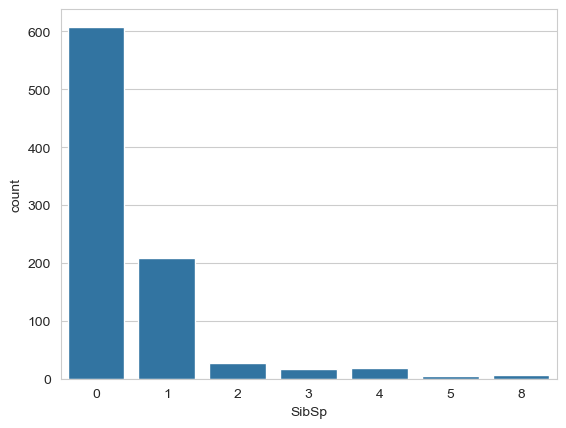

In [17]:
# nr of siblings and spounse onboard
sns.countplot(x='SibSp', data=train)
plt.show()

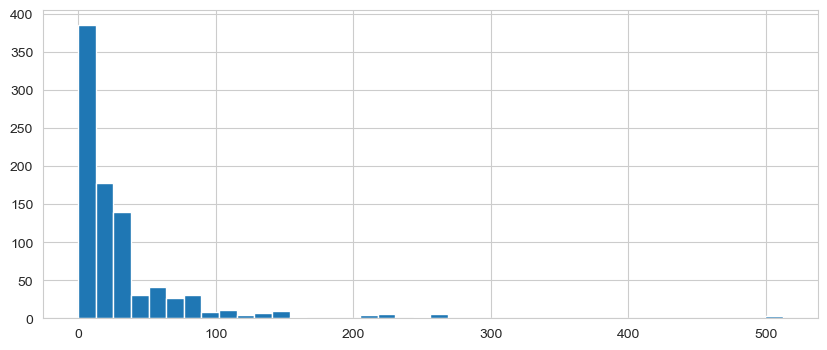

In [18]:
# see distribution of how much people pay
train['Fare'].hist(bins=40, figsize=(10,4))
plt.show()

In [19]:
import cufflinks as cf

In [20]:
cf.go_offline()

In [21]:
# now see interactive chart
train['Fare'].iplot(kind='hist', bins=30)

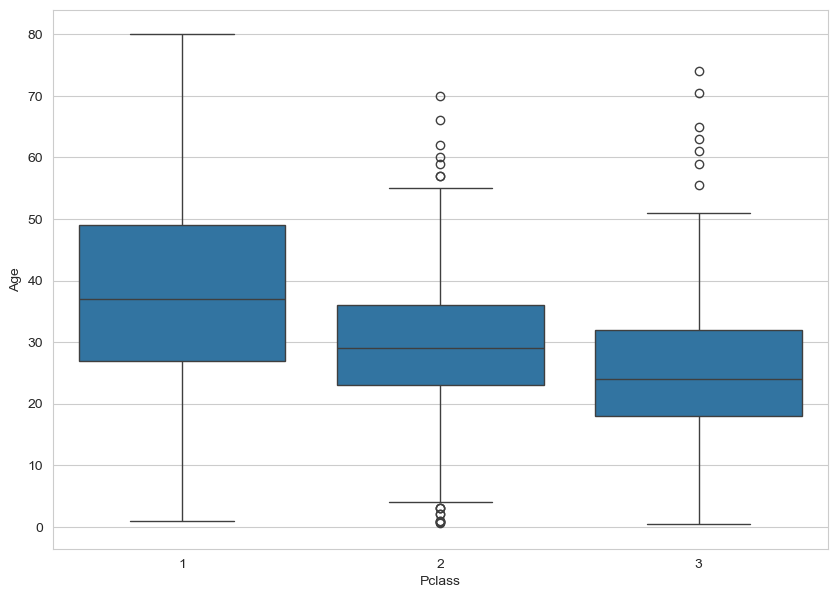

In [22]:
# create a boxplot 
plt.figure(figsize=(10,7))
sns.boxplot(x='Pclass', y='Age', data=train)
plt.show()

In [23]:
# create a function to fill in the missing age
# using the average of the Pclass the passenger was in
def impute_age(cols):
    Age = cols[0]
    Pclass = cols[1]
    if pd.isnull(Age):
        if Pclass == 1:
            return 37 #hard-coded value based on the boxplot
        elif Pclass == 2:
            return 29
        else:
            return 24
    else: 
        return Age

In [24]:
train['Age']=train[['Age','Pclass']].apply(impute_age, axis=1)

/var/folders/8d/vhbtv_xd50z9q4q9hrxff6500000gp/T/ipykernel_67342/2172627968.py:4: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`

/var/folders/8d/vhbtv_xd50z9q4q9hrxff6500000gp/T/ipykernel_67342/2172627968.py:5: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



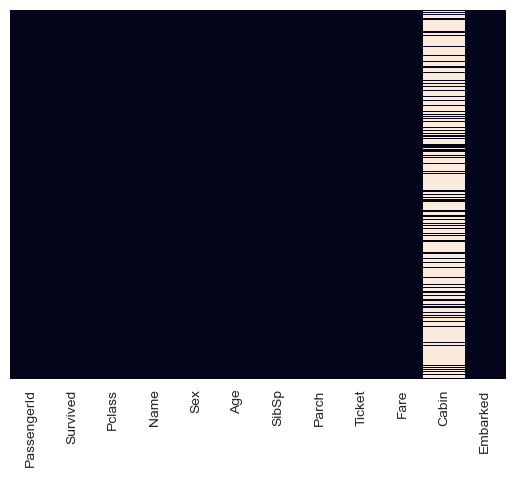

In [25]:
sns.heatmap(train.isnull(), yticklabels=False, cbar=False)
plt.show()

In [26]:
# there's too many missing values in Cabin column, let's drop it
train.drop('Cabin', axis=1, inplace=True)

In [27]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')

In [28]:
# drop missing values
train.dropna(inplace=True)

In [29]:
# to do the ML training model, we need to create dummy variables for string columns, eg: Sex, Pclass
# dummy variables need to be in numerical values, eg: 0, 1 
pd.get_dummies(train['Sex'])

,female,male
0,False,True
1,True,False
2,True,False
3,True,False
4,False,True
...,...,...
886,False,True
887,True,False
888,True,False
889,False,True


In [30]:
# we only need one column since the other one is completely dependent on the other column (or opposite)
sex = pd.get_dummies(train['Sex'], drop_first=True)

In [31]:
pd.get_dummies(train['Embarked'])

,C,Q,S
0,False,False,True
1,True,False,False
2,False,False,True
3,False,False,True
4,False,False,True
...,...,...,...
886,False,False,True
887,False,False,True
888,False,False,True
889,True,False,False


In [32]:
embark = pd.get_dummies(train['Embarked'], drop_first=True)

In [33]:
train = pd.concat([train, sex, embark], axis=1)

In [34]:
train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,male,Q,S
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,True,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,False,False,False
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,False,False,True
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S,True,False,True
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S,False,False,True
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,24.0,1,2,W./C. 6607,23.4500,S,False,False,True
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C,True,False,False


In [35]:
# drop string columns that we are not going to use
train.drop(['Sex', 'Embarked','Name','Ticket'], axis=1, inplace=True)

In [36]:
# we can drop the PassengerId since it's just a sequence of numericId for Passenger from 1 to x, doesn't help the model
train.drop('PassengerId', axis=1, inplace=True)

In [37]:
train.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,male,Q,S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


In [71]:
# you need to clean test data too, but going through lot of steps, that's why we use only train dataset here
x = train.drop('Survived', axis=1)
y=train['Survived']

In [73]:
from sklearn.model_selection import train_test_split

In [79]:
x_train, x_test, y_train, y_test = train_test_split( x, y, test_size=0.3, random_state=101)

In [81]:
from sklearn.linear_model import LogisticRegression

In [83]:
logmodel = LogisticRegression()

In [85]:
logmodel.fit(x_train, y_train)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



LogisticRegression()

In [87]:
predictions = logmodel.predict(x_test)

In [89]:
from sklearn.metrics import classification_report

In [91]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86       163
           1       0.82      0.71      0.76       104

    accuracy                           0.83       267
   macro avg       0.83      0.81      0.81       267
weighted avg       0.83      0.83      0.83       267



In [93]:
from sklearn.metrics import confusion_matrix

In [95]:
confusion_matrix(y_test, predictions)

array([[147,  16],
       [ 30,  74]])

In [ ]:
# to improve accuracy, maybe can use the entire dataset instead of a part (train)
# feature engineering: use the name and grab info from title, eg: Dr, Miss
# maybe location in the ship, ticket, cabin ...
